# Quartz / Si two-layer THz-TDS fit with **frequency-dependent** $n(\omega)$, $k(\omega)$

Extension of `QuartzSI_loss_landscape_Adam.ipynb`. Instead of one scalar $(n, k)$ per layer, each layer gets a
**low-order polynomial** in frequency, so the whole model is still only a handful of parameters
(no per-frequency unknowns, no huge Jacobians):

$$
n_j(f) = c_0 + a\,x + b\,x^2 + c\,x^3 \;\;\text{(4 coefficients per layer)}, \qquad
k_j(f) = c_0 + a\,x + b\,x^2 \;\;\text{(3 coefficients per layer)},
$$
$$
x = \frac{\mathrm{clip}(f, f_{lo}, f_{hi}) - f_{ref}}{f_{scale}}
$$

$n$ and $k$ each have their **own, independent** set of coefficients (the letters $c_0, a, b, c$ are reused as
names only — the code keeps them in two separate arrays, `n_coefs` `[2,4]` and `k_coefs` `[2,3]`).
The only powers in the model are the powers of the normalised frequency $x$.

* $x$ is a **normalised frequency** (default $f_{ref} = f_{scale} = 1$ THz), so all polynomial coefficients are
  $\mathcal{O}(1)$-comparable and $c_0$ is simply the index **at 1 THz**.
* Outside the usable band $[f_{lo}, f_{hi}]$ the polynomial is *frozen* at its band-edge value (the `clip`).
  There is no signal there, so those frequencies must not be allowed to drive the fit or blow up the
  transfer-matrix (a cubic extrapolated to 15 THz would).
* $k(f)$ is **not** hard-constrained to be positive (an absolute value would put cusps into $k(f)$ wherever the
  polynomial crosses zero, and THz data do legitimately push small stretches of $k$ slightly negative). Instead a
  **soft penalty** is added to the loss,
  $\lambda_k \,\langle \max(0, -k_j(f)) \rangle_{f \in \text{band}}$, which only *nudges* $k$ towards $\ge 0$
  and leaves the function smooth. `K_POS_WEIGHT` sets $\lambda_k$ (0 switches it off). A slightly negative $k$ is
  numerically harmless: the gain of a 1 mm layer with $k=-0.001$ at 3 THz is $e^{2\pi f |k| d / c} \approx 1.06$.
* Thicknesses $d_1, d_2$ are still free parameters (switch `FIT_THICKNESS = False` to pin them).

For quartz and silicon, which are almost dispersion-free in this range, $c_0$ carries nearly all the information;
the higher-order terms should come out small — the notebook fits **flat first (c₀ + d only)**, then unlocks
$a, b$ (and $c$ for $n$) from that solution, so you can see directly how much the dispersion terms buy you.

The forward model, loss, optimizer and plotting style are kept from the original notebook; `Simulate.py` is
imported unchanged (only `RTm_batched` is reused — the per-frequency layer builder is defined here).

In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))

In [2]:
# Interactive figures need the `ipympl` package; otherwise VS Code / Jupyter render inline.
try:
    import ipympl  # noqa
    %matplotlib widget
except ImportError:
    %matplotlib inline

In [3]:
from tqdm.auto import tqdm

import numpy as np
import matplotlib.pyplot as plt
import torch

from Simulate import RTm_batched, simulate_from_signal
from data_quartzsi import t_r_raw as t_r, A_r, A_s

torch.set_default_dtype(torch.float32)
c_light = 299792458.0

## 1. Data (or synthetic dispersive test case)

In [4]:
simulate_data = False      # True -> build a synthetic sample with KNOWN n(f), k(f) to test recovery

In [5]:
# Global variables shared by everything below
L = len(A_r)                      # 2425 points
deltat = (t_r[1] - t_r[0]) * 1e-12
t_r = t_r - t_r[0]

x_exp = np.asarray(A_r, dtype=np.float32)          # reference pulse
true_x_exp = np.asarray(A_s, dtype=np.float32)     # sample pulse (overwritten if simulate_data)

# FFT grid used by the forward model (same convention as Simulate.simulate_parallel: M = 2L, N = 4L)
M = 2 * L
N = 4 * L
deltaf = 1.0 / (N * deltat)
dk = 2 * np.pi * deltaf / c_light
k_vals = torch.arange(M + 1, dtype=torch.float32)          # frequency index
f_THz = (k_vals * deltaf / 1e12)                           # frequency axis of T(f), THz
f_np = f_THz.numpy()

print(f"L = {L}, dt = {deltat*1e15:.1f} fs, df = {deltaf/1e9:.2f} GHz, f_max(T grid) = {f_np[-1]:.1f} THz")

L = 2425, dt = 33.0 fs, df = 3.12 GHz, f_max(T grid) = 15.2 THz


## 2. Polynomial $n(f)$, $k(f)$ and the dispersive forward model

In [33]:
# ---- normalised frequency ----------------------------------------------------------
F_REF   = 1.0    # THz : c0 is the index at this frequency
F_SCALE = 1.0    # THz : width used to normalise the polynomial variable
F_LO, F_HI = 0.2, 4   # THz : band where the data carries information (checked against the spectrum below)

def xnorm(f):
    '''Normalised, band-clipped frequency variable x(f). Works for torch tensors and numpy arrays.'''
    if isinstance(f, torch.Tensor):
        return (torch.clamp(f, F_LO, F_HI) - F_REF) / F_SCALE
    return (np.clip(f, F_LO, F_HI) - F_REF) / F_SCALE

def poly(coefs, x):
    '''Polynomial in x of any order: coefs[0] + coefs[1] x + coefs[2] x^2 + ...  (Horner scheme).
    Used with 4 coefficients (c0, a, b, c) for n and 3 coefficients (c0, a, b) for k.'''
    out = coefs[len(coefs) - 1]
    for i in range(len(coefs) - 2, -1, -1):
        out = out * x + coefs[i]
    return out

poly4 = poly   # alias kept for readability where 4 coefficients are meant


# ---- per-frequency transfer function / time-domain pulse -----------------------------
def simulate_dispersive(x, layers, deltat):
    '''
    Same algorithm as Simulate.simulate_parallel, but each layer is (n_complex, d) where n_complex may be
    a torch tensor of shape [M+1] (one complex index per frequency of the T grid) or a scalar.

    Returns (T [N] complex, y [N] real).  y[:L] is the simulated sample pulse.
    '''
    xt = torch.as_tensor(x, dtype=torch.float32)
    device = xt.device
    n0 = torch.tensor(1.0, dtype=torch.cfloat, device=device)

    batched_layers = []
    for nj, d in layers:
        nj = torch.as_tensor(nj, dtype=torch.cfloat, device=device)
        if nj.ndim == 0:
            nj = nj.expand(M + 1)
        kD = dk * k_vals * d                                # [M+1], real (d may carry a gradient)
        batched_layers.append((nj, kD))

    _, T_half = RTm_batched(len(batched_layers), n0, batched_layers)

    T = torch.zeros(N, dtype=torch.cfloat, device=device)
    T[:M + 1] = T_half
    T[M + 1:] = torch.conj(torch.flip(T[1:M], dims=[0]))    # Hermitian symmetry for a real pulse

    z = torch.zeros(N, dtype=torch.float32, device=device)
    z[:L] = xt
    X = torch.fft.fft(z) / N
    y = N * torch.fft.ifft(T * X).real
    return T, y

In [34]:
# Consistency check: with flat (scalar) indices the new simulator must reproduce Simulate.simulate_from_signal
layers_flat = [(1.982 - 0.0071j, 1e-3), (3.4 - 0.0054j, 0.4e-3)]
_, y_old = simulate_from_signal(x_exp, layers_flat, deltat)
_, y_new = simulate_dispersive(x_exp, [(torch.tensor(n), torch.tensor(d)) for n, d in layers_flat], deltat)
print("max |y_new - y_old| =", (y_new - y_old).abs().max().item(), " (should be ~1e-7)")

max |y_new - y_old| = 0.0  (should be ~1e-7)


In [35]:
if simulate_data:
    # Synthetic sample with a KNOWN dispersion, to verify the fit recovers it.
    true_coefs = {
        'n1': [1.96, 0.010, 0.004, 0.0],  'k1': [0.005, 0.006, 0.0],       # n: c0,a,b,c   k: c0,a,b
        'n2': [3.415, 0.002, 0.0, 0.0],   'k2': [0.0005, 0.0005, 0.0],
        'd':  [0.980e-3, 0.400e-3],
    }
    xf = xnorm(f_THz)
    layers_true = []
    for j in (1, 2):
        n = poly(torch.tensor(true_coefs[f'n{j}']), xf)
        k = poly(torch.tensor(true_coefs[f'k{j}']), xf)
        layers_true.append((n - 1j * k, torch.tensor(true_coefs['d'][j - 1])))
    _, y_true = simulate_dispersive(x_exp, layers_true, deltat)
    rng = np.random.default_rng(0)
    true_x_exp = (y_true[:L].numpy() + 0.002 * rng.standard_normal(L)).astype(np.float32)
else:
    true_coefs = None

## 3. Where is the signal? (choose $f_{lo}$, $f_{hi}$)

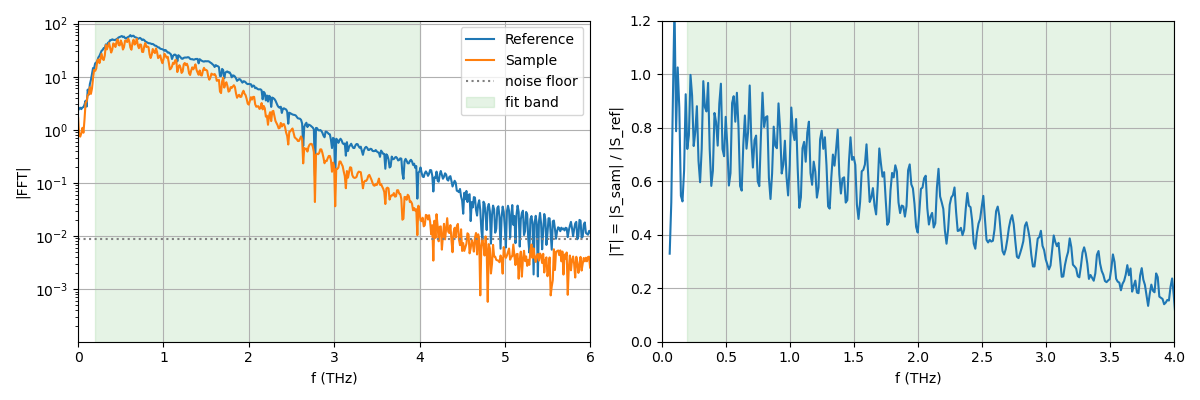

In [36]:
f_data = np.fft.rfftfreq(L, deltat) / 1e12
S_ref = np.abs(np.fft.rfft(x_exp))
S_sam = np.abs(np.fft.rfft(true_x_exp))
noise_floor = np.median(S_ref[f_data > 6.0])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(f_data, S_ref, label='Reference')
ax[0].semilogy(f_data, S_sam, label='Sample')
ax[0].axhline(noise_floor, color='gray', ls=':', label='noise floor')
ax[0].axvspan(F_LO, F_HI, color='C2', alpha=0.12, label='fit band')
ax[0].set_xlim(0, 6); ax[0].set_xlabel('f (THz)'); ax[0].set_ylabel('|FFT|'); ax[0].legend(); ax[0].grid()

ok = (f_data > 0.05)
ax[1].plot(f_data[ok], (S_sam / S_ref)[ok])
ax[1].axvspan(F_LO, F_HI, color='C2', alpha=0.12)
ax[1].set_xlim(0, 4); ax[1].set_ylim(0, 1.2); ax[1].set_xlabel('f (THz)'); ax[1].set_ylabel('|T| = |S_sam| / |S_ref|'); ax[1].grid()
plt.tight_layout(); plt.show()

## 4. Parametrised two-layer model

Every physical coefficient is written as `init + raw * scale` with the trainable `raw` starting at 0.
This is the same trick as the original notebook (`n1 * n10`) but it also works for coefficients whose
initial value is 0, and it lets one Adam learning rate act sensibly on quantities that differ by orders
of magnitude ($n \sim 2$, $k \sim 10^{-2}$, $d \sim 10^{-3}$ m). A boolean `mask` freezes coefficients
without touching `requires_grad`, so the flat stage and the dispersive stage share the same optimizer set-up.

In [37]:
N_COEF_NAMES = ['c0', 'a', 'b', 'c']     # n: cubic
K_COEF_NAMES = ['c0', 'a', 'b']          # k: quadratic
N_ORDER, K_ORDER = len(N_COEF_NAMES), len(K_COEF_NAMES)

class DispersiveTwoLayer:
    def __init__(self, n_init, k_init, d_init,
                 n_scale=(None, 0.1, 0.1, 0.1),       # None -> use the init value itself (relative step, like the original)
                 k_scale=(None, 0.005, 0.005),
                 d_scale=None):
        self.n_init = torch.tensor([[n_init[j], 0., 0., 0.] for j in range(2)])
        self.k_init = torch.tensor([[k_init[j], 0., 0.] for j in range(2)])
        self.d_init = torch.tensor(list(d_init), dtype=torch.float32)

        self.n_scale = torch.tensor([[n_init[j] if n_scale[0] is None else n_scale[0], *n_scale[1:]] for j in range(2)])
        self.k_scale = torch.tensor([[k_init[j] if k_scale[0] is None else k_scale[0], *k_scale[1:]] for j in range(2)])
        self.d_scale = self.d_init.clone() if d_scale is None else torch.tensor(d_scale, dtype=torch.float32)

        # trainable, all start at 0
        self.n_raw = torch.zeros(2, N_ORDER, requires_grad=True)
        self.k_raw = torch.zeros(2, K_ORDER, requires_grad=True)
        self.d_raw = torch.zeros(2, requires_grad=True)

        # masks: 1 = free, 0 = frozen
        self.n_mask = torch.ones(2, N_ORDER); self.k_mask = torch.ones(2, K_ORDER); self.d_mask = torch.ones(2)
        self.xf = xnorm(f_THz)
        self.band = (f_THz >= F_LO) & (f_THz <= F_HI)       # frequencies used by the k>=0 penalty

    # ---- configuration helpers ---------------------------------------------------
    def parameters(self):
        return [self.n_raw, self.k_raw, self.d_raw]

    def set_dispersion(self, free: bool):
        '''Free or freeze the dispersion terms (a, b, c of n; a, b of k). c0 always free.'''
        v = 1.0 if free else 0.0
        self.n_mask[:, 1:] = v; self.k_mask[:, 1:] = v

    def set_thickness(self, free: bool):
        self.d_mask[:] = 1.0 if free else 0.0

    def set_absorption(self, free: bool):
        self.k_mask[:] = 1.0 if free else 0.0

    # ---- physical quantities -------------------------------------------------------
    def n_coefs(self): return self.n_init + self.n_raw * self.n_scale * self.n_mask      # [2,4]
    def k_coefs(self): return self.k_init + self.k_raw * self.k_scale * self.k_mask      # [2,3]
    def d(self):       return self.d_init + self.d_raw * self.d_scale * self.d_mask      # [2]

    def nk(self, f=None):
        '''n(f), k(f) for both layers on the T-grid (or on a user-supplied frequency axis, THz).'''
        x = self.xf if f is None else xnorm(torch.as_tensor(f, dtype=torch.float32))
        nc, kc = self.n_coefs(), self.k_coefs()
        n = torch.stack([poly(nc[j], x) for j in range(2)])
        k = torch.stack([poly(kc[j], x) for j in range(2)])        # no |.| : k may go slightly negative
        return n, k

    def layers(self):
        n, k = self.nk(); d = self.d()
        return [(n[j] - 1j * k[j], d[j]) for j in range(2)]

    def forward(self, x):
        T, y = simulate_dispersive(x, self.layers(), deltat)
        return T, y[:L]

    def k_negativity(self):
        '''Mean of max(0, -k(f)) over the fit band and both layers: the quantity penalised in the loss.'''
        _, k = self.nk()
        return torch.relu(-k[:, self.band]).mean()

    def k_negative_fraction(self):
        '''Diagnostic: fraction of band frequencies where k(f) < 0, per layer.'''
        with torch.no_grad():
            _, k = self.nk()
            return (k[:, self.band] < 0).float().mean(dim=1).numpy()

    # ---- bookkeeping ----------------------------------------------------------------
    def state(self):
        with torch.no_grad():
            return dict(n=self.n_coefs().clone(), k=self.k_coefs().clone(), d=self.d().clone())

    def load_state(self, st):
        '''Re-initialise so that the current physical values become the new 'init' (raw -> 0). Used between stages.'''
        with torch.no_grad():
            self.n_init = st['n'].clone(); self.k_init = st['k'].clone(); self.d_init = st['d'].clone()
            self.n_raw.zero_(); self.k_raw.zero_(); self.d_raw.zero_()
            self.d_scale = self.d_init.clone()

    def report(self, coefs_true=None):
        st = self.state()
        for j in range(2):
            n = ', '.join(f"{v:+.5f}" for v in st['n'][j].tolist())
            k = ', '.join(f"{v:+.5f}" for v in st['k'][j].tolist())
            print(f"layer {j+1}:  n(x) coefs [c0,a,b,c] = [{n}]")
            print(f"           k(x) coefs [c0,a,b]   = [{k}]      d = {st['d'][j].item()*1e6:8.2f} um")
        neg = self.k_negative_fraction()
        print(f"fraction of band with k<0: layer1 {neg[0]*100:.1f} %, layer2 {neg[1]*100:.1f} %")
        if coefs_true is not None:
            print("true:", coefs_true)

## 5. Loss and optimizer loop

In [38]:
def mae_loss(y_test, y_pred):
    return np.mean(np.abs(y_test - y_pred))

def log_cosh_loss(y_pred, y_test):
    diff = y_pred - y_test
    return torch.mean(torch.log(torch.cosh(diff + 1e-12)))

def data_loss(y_pred, y_test):
    # identical to the original notebook: MAE + log-cosh
    return (y_test - y_pred).abs().mean() + log_cosh_loss(y_pred, y_test)

K_POS_WEIGHT = 0.5     # lambda_k : weight of the soft k>=0 penalty. 0 -> no penalty at all.

def total_loss(y_pred, y_test, model=None):
    '''data loss + soft positivity nudge on k(f).
    The penalty is a hinge: K_POS_WEIGHT * mean over the band of max(0, -k). It is exactly zero while k >= 0
    everywhere (so a positive solution is untouched) and grows linearly with the depth of a negative excursion,
    i.e. it pushes back with a constant force K_POS_WEIGHT instead of forbidding k<0. With k ~ 1e-2 and a data loss
    ~ 3e-3, K_POS_WEIGHT = 1 makes a -1e-3 dip over half the band cost ~5e-4, a visible but not dominant nudge.'''
    loss = data_loss(y_pred, y_test)
    if model is not None and K_POS_WEIGHT > 0:
        loss = loss + K_POS_WEIGHT * model.k_negativity()
    return loss

In [39]:
def fit(model, n_iters=20000, lr=1e-4, print_step=2000, label=''):
    '''
    Adam on the raw parameters of `model`. Returns a trajectory dict with per-iteration histories:
      traj['n']  [iters, 2, 4]   polynomial coefficients of n for both layers (c0, a, b, c)
      traj['k']  [iters, 2, 3]   polynomial coefficients of k for both layers (c0, a, b)
      traj['penalty'] [iters]    K_POS_WEIGHT * <max(0,-k)> part of the loss
      traj['d']  [iters, 2]
      traj['loss'] [iters]
    '''
    y_meas = torch.as_tensor(true_x_exp, dtype=torch.float32)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {'n': [], 'k': [], 'd': [], 'loss': [], 'penalty': []}

    def record(loss):
        st = model.state()
        hist['n'].append(st['n'].numpy()); hist['k'].append(st['k'].numpy())
        hist['d'].append(st['d'].numpy()); hist['loss'].append(loss.item())
        with torch.no_grad():
            hist['penalty'].append(K_POS_WEIGHT * model.k_negativity().item())

    _, y = model.forward(x_exp)
    loss = total_loss(y, y_meas, model)
    record(loss)
    print(f"[{label}] Epoch={1:6d}  loss={loss.item():.4e}")

    for i in tqdm(range(1, n_iters), desc=f'fit {label}', leave=False):
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        _, y = model.forward(x_exp)
        loss = total_loss(y, y_meas, model)

        with torch.no_grad():
            record(loss)
            if i == n_iters - 1 or (i + 1) % print_step == 0:
                st = model.state()
                print(f"[{label}] Epoch={i+1:6d}  loss={loss.item():.4e} (k-penalty {hist['penalty'][-1]:.1e})  "
                      f"n1(1THz)={st['n'][0,0]:.5f} k1={st['k'][0,0]:.5f} d1={st['d'][0]*1e6:.1f}um  "
                      f"n2(1THz)={st['n'][1,0]:.5f} k2={st['k'][1,0]:.5f} d2={st['d'][1]*1e6:.1f}um")

    return {key: np.array(v) for key, v in hist.items()}

## 6. Plot helpers

In [40]:
def plot_loss(trajs, labels):
    plt.figure(figsize=(10, 3.5))
    off = 0
    for traj, lab in zip(trajs, labels):
        plt.plot(np.arange(off, off + len(traj['loss'])), traj['loss'], label=lab)
        off += len(traj['loss'])
    off = 0
    for traj, lab in zip(trajs, labels):
        if np.any(traj['penalty'] > 0):
            plt.plot(np.arange(off, off + len(traj['penalty'])), traj['penalty'], ls=':', label=f'{lab}: k-penalty part')
        off += len(traj['loss'])
    plt.yscale('log'); plt.xlabel('Iteration'); plt.ylabel('Loss'); plt.legend(); plt.grid(); plt.title('Optimization')
    plt.show()


def plot_pulses(model, title='Sample pulse: experiment vs dispersive model'):
    with torch.no_grad():
        _, y = model.forward(x_exp)
    y = y.numpy()
    print(f"MAE = {mae_loss(true_x_exp, y):.4e}")
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    ax[0].plot(t_r, true_x_exp, label='Sample Pulse (Experimental)', color='C1')
    ax[0].plot(t_r, y, label='Sample Pulse (Simulated, n(f), k(f))', color='black', alpha=0.75, ls='--')
    ax[0].set_title(title); ax[0].legend(); ax[0].grid()
    ax[1].plot(t_r, true_x_exp - y, color='C3', lw=0.8); ax[1].set_ylabel('residual'); ax[1].set_xlabel('t (ps)'); ax[1].grid()
    plt.tight_layout(); plt.show()


def plot_nk(models, labels, f_plot=np.linspace(0.05, 4.0, 400), true_coefs=None):
    '''n(f) and k(f) of both layers for one or several fitted models; the fit band is shaded.'''
    fig, ax = plt.subplots(2, 2, figsize=(12, 7))
    xt = xnorm(f_plot)
    for m, lab in zip(models, labels):
        with torch.no_grad():
            n, k = m.nk(f_plot)
        for j in range(2):
            ax[0, j].plot(f_plot, n[j].numpy(), label=lab)
            ax[1, j].plot(f_plot, k[j].numpy(), label=lab)
    if true_coefs is not None:
        for j in range(2):
            ax[0, j].plot(f_plot, poly(true_coefs[f'n{j+1}'], xt), 'k:', label='true')
            ax[1, j].plot(f_plot, poly(true_coefs[f'k{j+1}'], xt), 'k:', label='true')
    for j, name in enumerate(['layer 1 (quartz)', 'layer 2 (Si)']):
        for i, q in enumerate(['n', 'k']):
            a = ax[i, j]
            a.axvspan(F_LO, F_HI, color='C2', alpha=0.10)
            a.set_xlabel('f (THz)'); a.set_ylabel(f'{q}(f)'); a.grid(); a.legend()
            if q == 'k': a.axhline(0, color='k', lw=0.6)
        ax[0, j].set_title(name)
    plt.tight_layout(); plt.show()


def plot_spectral_residual(models, labels):
    '''|FFT| of the residual: tells you in which band the model still disagrees with the data.'''
    plt.figure(figsize=(10, 3.5))
    plt.semilogy(f_data, S_sam, color='gray', alpha=0.5, label='|sample spectrum|')
    for m, lab in zip(models, labels):
        with torch.no_grad():
            _, y = m.forward(x_exp)
        plt.semilogy(f_data, np.abs(np.fft.rfft(true_x_exp - y.numpy())), label=f'|residual| {lab}')
    plt.axvspan(F_LO, F_HI, color='C2', alpha=0.10)
    plt.xlim(0, 5); plt.xlabel('f (THz)'); plt.legend(); plt.grid(); plt.show()


def plot_coef_history(traj, title=''):
    fig, ax = plt.subplots(2, 2, figsize=(12, 6))
    for j in range(2):
        for i, nm in enumerate(N_COEF_NAMES):
            ax[0, j].plot(traj['n'][:, j, i] - traj['n'][0, j, i], label=f'n: {nm} - {nm}(0)')
        for i, nm in enumerate(K_COEF_NAMES):
            ax[1, j].plot(traj['k'][:, j, i] - traj['k'][0, j, i], label=f'k: {nm} - {nm}(0)')
        ax[0, j].set_title(f'layer {j+1} {title}'); ax[0, j].legend(fontsize=8); ax[0, j].grid()
        ax[1, j].legend(fontsize=8); ax[1, j].grid(); ax[1, j].set_xlabel('iteration')
    plt.tight_layout(); plt.show()

## 7. Stage 1 — flat fit ($c_0$ and $d$ only)

Reproduces the original 6-parameter problem. Its solution is the starting point for the dispersive stage.

In [41]:
n_init = [1.9820, 3.4000]
k_init = [0.0071, 0.0054]
d_init = [  1e-3, 0.4e-3]

FIT_THICKNESS = True
N_ITERS_FLAT = 15000
N_ITERS_DISP = 30000
LR = 1e-4

[flat] Epoch=     1  loss=4.6598e-02


fit flat:   0%|          | 0/14999 [00:00<?, ?it/s]

[flat] Epoch=  2500  loss=5.3336e-03 (k-penalty 0.0e+00)  n1(1THz)=1.98246 k1=0.00538 d1=984.9um  n2(1THz)=3.36832 k2=0.00409 d2=390.3um
[flat] Epoch=  5000  loss=4.6404e-03 (k-penalty 0.0e+00)  n1(1THz)=1.96942 k1=0.00408 d1=991.5um  n2(1THz)=3.42199 k2=0.00298 d2=384.3um
[flat] Epoch=  7500  loss=4.5249e-03 (k-penalty 0.0e+00)  n1(1THz)=1.95713 k1=0.00393 d1=997.8um  n2(1THz)=3.47905 k2=0.00227 d2=377.9um
[flat] Epoch= 10000  loss=4.4960e-03 (k-penalty 0.0e+00)  n1(1THz)=1.95686 k1=0.00427 d1=998.0um  n2(1THz)=3.47965 k2=0.00135 d2=377.8um
[flat] Epoch= 12500  loss=4.4675e-03 (k-penalty 0.0e+00)  n1(1THz)=1.95880 k1=0.00473 d1=996.9um  n2(1THz)=3.47114 k2=0.00022 d2=378.8um
[flat] Epoch= 15000  loss=4.4630e-03 (k-penalty 0.0e+00)  n1(1THz)=1.95982 k1=0.00481 d1=996.4um  n2(1THz)=3.46674 k2=0.00000 d2=379.2um
layer 1:  n(x) coefs [c0,a,b,c] = [+1.95982, +0.00000, +0.00000, +0.00000]
           k(x) coefs [c0,a,b]   = [+0.00481, +0.00000, +0.00000]      d =   996.44 um
layer 2:  n(x) c

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_64967/123333914.py:21: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})


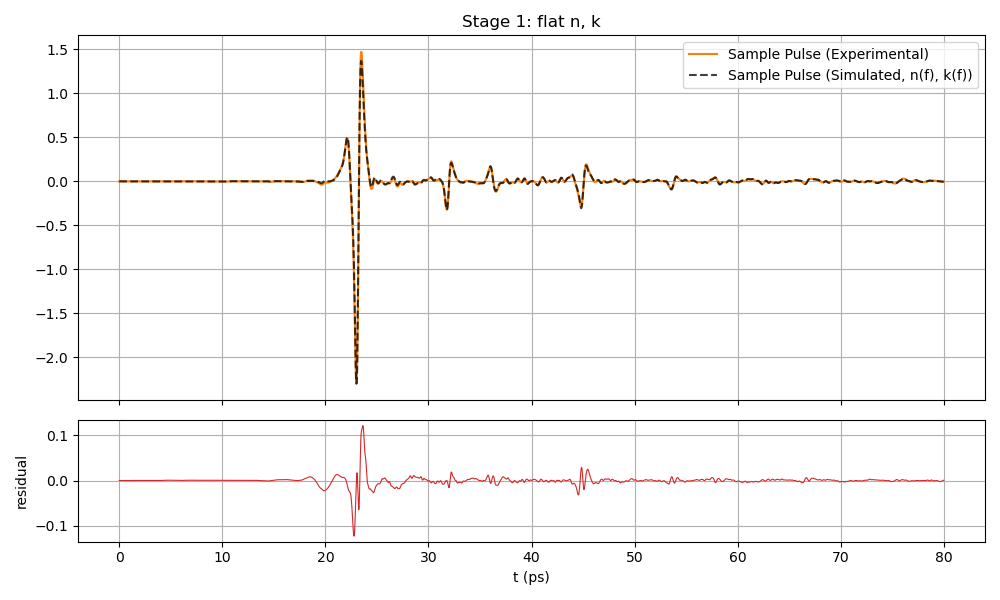

In [42]:
model = DispersiveTwoLayer(n_init, k_init, d_init)
model.set_dispersion(False)          # a, b, (c) frozen -> flat n, k
model.set_thickness(FIT_THICKNESS)

traj_flat = fit(model, n_iters=N_ITERS_FLAT, lr=LR, print_step=2500, label='flat')
model.report()
plot_pulses(model, title='Stage 1: flat n, k')

## 8. Stage 2 — unlock dispersion ($a, b, c$ of $n$ and $a, b$ of $k$, both layers)

Starts from the stage-1 solution. The flat model is kept as `model_flat` for comparison.

In [43]:
import copy
model_flat = copy.deepcopy(model)     # frozen snapshot of the flat solution

model.load_state(model.state())       # make the stage-1 result the new 'init' (raw -> 0, fresh Adam moments)
model.set_dispersion(True)
model.set_thickness(FIT_THICKNESS)

traj_disp = fit(model, n_iters=N_ITERS_DISP, lr=LR, print_step=5000, label='dispersive')
model.report(true_coefs)

[dispersive] Epoch=     1  loss=4.4630e-03


fit dispersive:   0%|          | 0/29999 [00:00<?, ?it/s]

[dispersive] Epoch=  5000  loss=3.1404e-03 (k-penalty 1.1e-05)  n1(1THz)=1.96450 k1=0.00397 d1=994.6um  n2(1THz)=3.44948 k2=0.00054 d2=381.1um
[dispersive] Epoch= 10000  loss=2.9596e-03 (k-penalty 1.7e-06)  n1(1THz)=1.96664 k1=0.00425 d1=993.7um  n2(1THz)=3.43553 k2=0.00032 d2=382.7um
[dispersive] Epoch= 15000  loss=2.9091e-03 (k-penalty 4.9e-07)  n1(1THz)=1.96679 k1=0.00430 d1=994.0um  n2(1THz)=3.43389 k2=-0.00000 d2=382.8um
[dispersive] Epoch= 20000  loss=2.9089e-03 (k-penalty 5.7e-07)  n1(1THz)=1.96708 k1=0.00430 d1=993.8um  n2(1THz)=3.43251 k2=-0.00000 d2=383.0um
[dispersive] Epoch= 25000  loss=2.9089e-03 (k-penalty 5.9e-07)  n1(1THz)=1.96709 k1=0.00430 d1=993.8um  n2(1THz)=3.43250 k2=-0.00000 d2=383.0um
[dispersive] Epoch= 30000  loss=2.9114e-03 (k-penalty 5.7e-07)  n1(1THz)=1.96709 k1=0.00430 d1=993.8um  n2(1THz)=3.43254 k2=-0.00000 d2=383.0um
layer 1:  n(x) coefs [c0,a,b,c] = [+1.96709, +0.00367, -0.00674, +0.00280]
           k(x) coefs [c0,a,b]   = [+0.00430, +0.00554, -0.0003

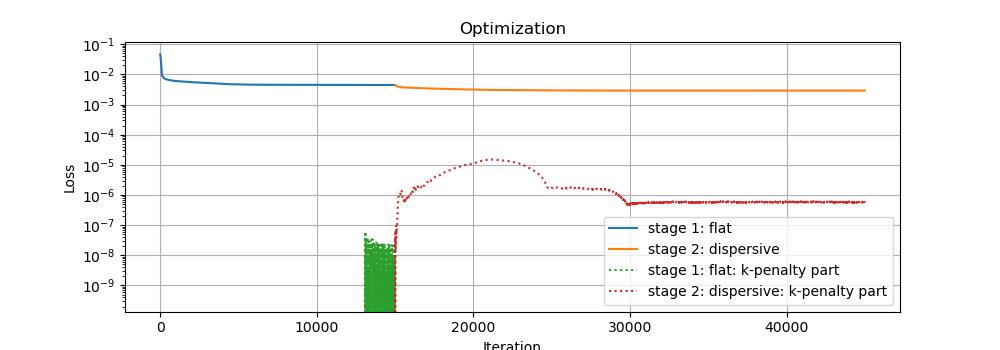

MAE = 2.8948e-03


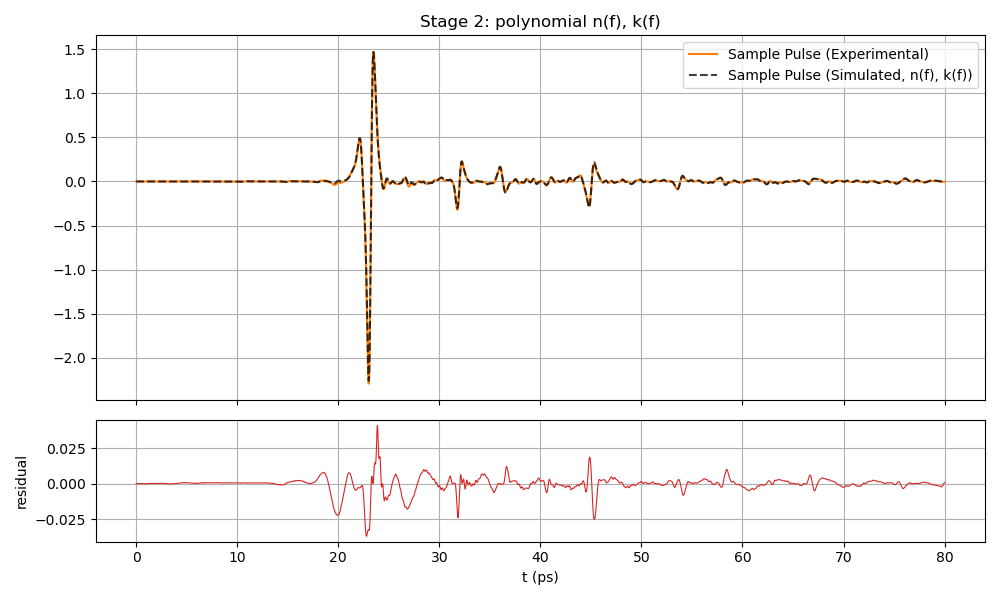

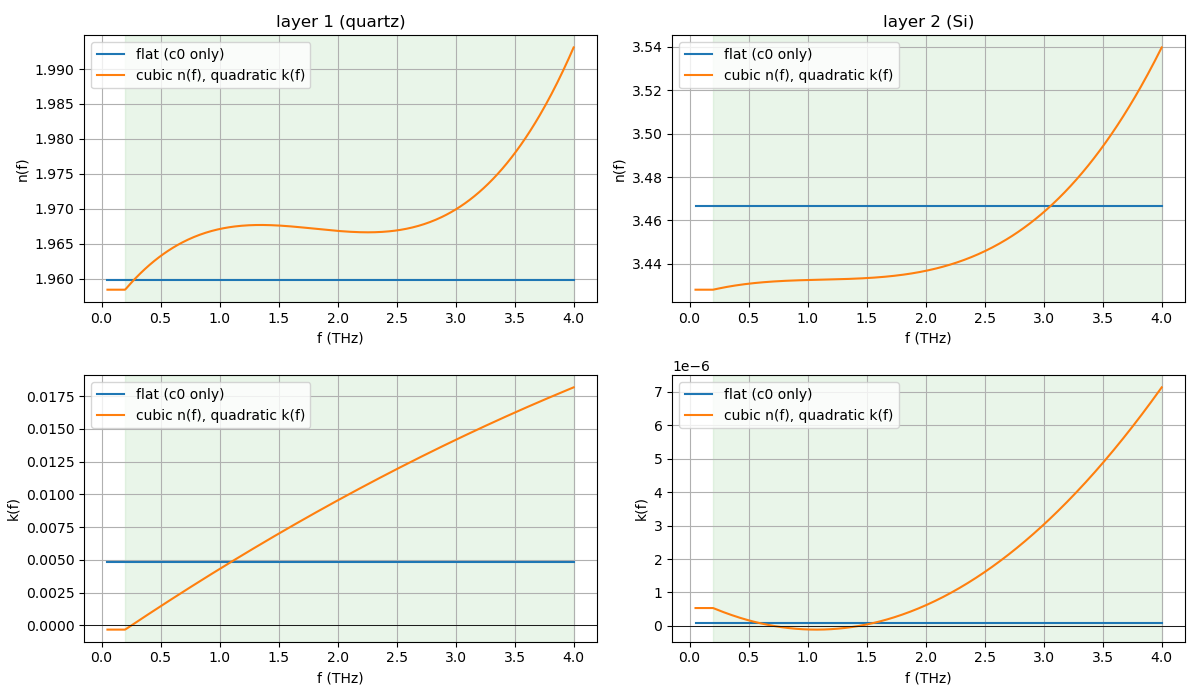

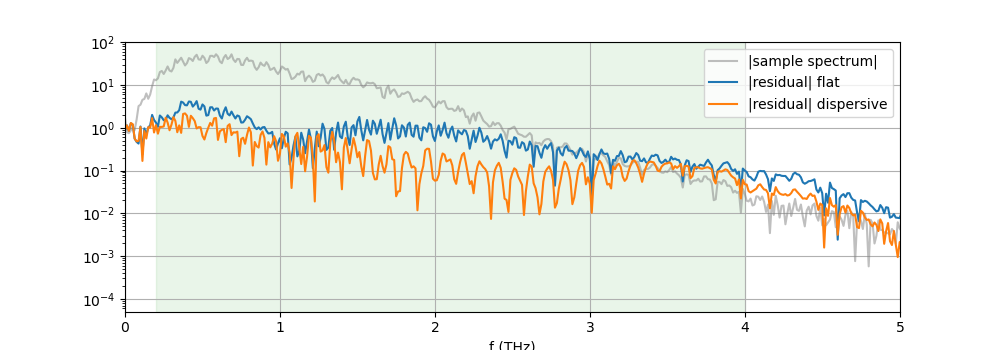

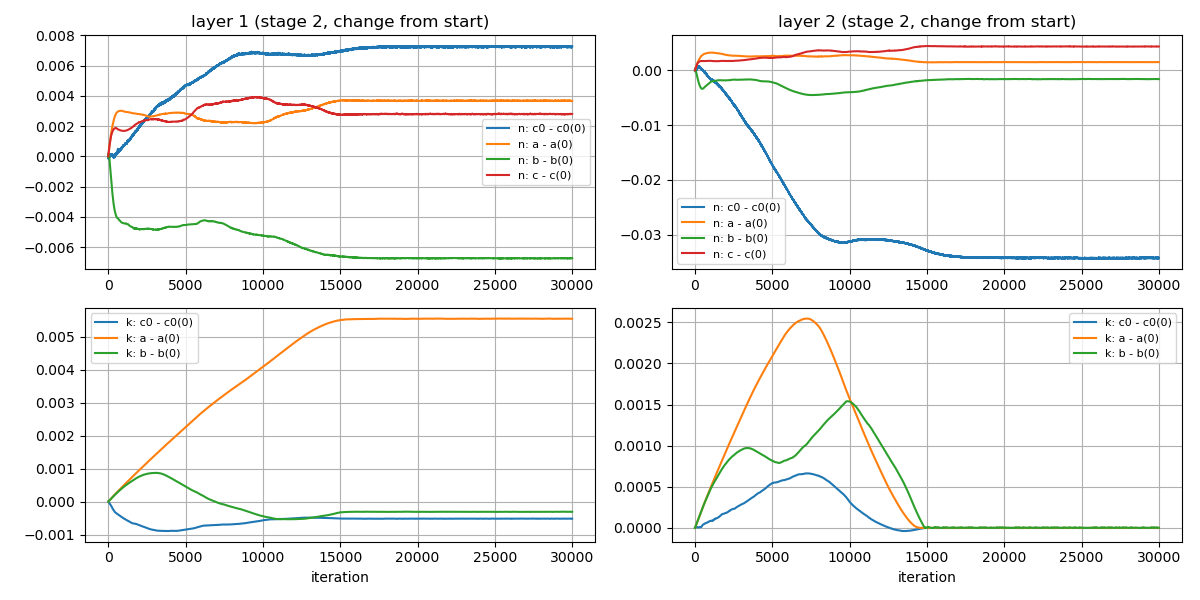

In [44]:
plot_loss([traj_flat, traj_disp], ['stage 1: flat', 'stage 2: dispersive'])
plot_pulses(model, title='Stage 2: polynomial n(f), k(f)')
plot_nk([model_flat, model], ['flat (c0 only)', 'cubic n(f), quadratic k(f)'], true_coefs=true_coefs)
plot_spectral_residual([model_flat, model], ['flat', 'dispersive'])
plot_coef_history(traj_disp, '(stage 2, change from start)')

## 9. Alternative: everything free from the start (single stage)

Useful to check that the two-stage path did not trap the fit; in a well-conditioned case both end at the same
$n(f)$, $k(f)$. Compare the final losses.

In [45]:
RUN_SINGLE_STAGE = False

if RUN_SINGLE_STAGE:
    model_1s = DispersiveTwoLayer(n_init, k_init, d_init)
    model_1s.set_dispersion(True); model_1s.set_thickness(FIT_THICKNESS)
    traj_1s = fit(model_1s, n_iters=N_ITERS_FLAT + N_ITERS_DISP, lr=LR, print_step=5000, label='single-stage')
    model_1s.report()
    plot_nk([model, model_1s], ['two-stage', 'single-stage'], true_coefs=true_coefs)
    print(f"final loss two-stage {traj_disp['loss'][-1]:.4e}   single-stage {traj_1s['loss'][-1]:.4e}")

## 10. Export $n(f)$, $k(f)$ tables and coefficients

The optical-path degeneracy of the original problem is still there: $n_j$ and $d_j$ trade against each other
(only $n_j d_j$ is tightly constrained by the pulse delay; the Fabry-Pérot echoes break the degeneracy weakly).
If you know a thickness from an independent measurement, set `FIT_THICKNESS = False` and put it in `d_init`.

In [46]:
f_out = np.arange(F_LO, F_HI + 1e-9, 0.01)
with torch.no_grad():
    n_out, k_out = model.nk(f_out)
    n_out, k_out = n_out.numpy(), k_out.numpy()

table = np.column_stack([f_out, n_out[0], k_out[0], n_out[1], k_out[1]])
np.savetxt('QuartzSi_nk_of_f.txt', table, fmt='%.6e',
           header='f_THz  n_quartz  k_quartz  n_Si  k_Si   (polynomial fit, x=(f-%.2f)/%.2f clipped to [%.2f,%.2f] THz)'
                  % (F_REF, F_SCALE, F_LO, F_HI))

st = model.state()
np.savez('QuartzSi_poly_coefs.npz', n_coefs=st['n'].numpy(), k_coefs=st['k'].numpy(), d=st['d'].numpy(),
         F_REF=F_REF, F_SCALE=F_SCALE, F_LO=F_LO, F_HI=F_HI)
print(table[::50])

[[ 2.00000000e-01  1.95840430e+00 -3.30929644e-04  3.42808223e+00
   5.34218259e-07]
 [ 7.00000000e-01  1.96530676e+00  2.60923873e-03  3.43182778e+00
   7.25410843e-09]
 [ 1.20000000e+00  1.96757793e+00  5.39631862e-03  3.43281031e+00
  -9.69399210e-08]
 [ 1.70000000e+00  1.96731937e+00  8.03030934e-03  3.43428636e+00
   2.21636157e-07]
 [ 2.20000000e+00  1.96663237e+00  1.05112111e-02  3.43951154e+00
   9.62982313e-07]
 [ 2.70000000e+00  1.96761847e+00  1.28390230e-02  3.45174265e+00
   2.12709847e-06]
 [ 3.20000000e+00  1.97237921e+00  1.50137469e-02  3.47423530e+00
   3.71398482e-06]
 [ 3.70000000e+00  1.98301589e+00  1.70353819e-02  3.51024580e+00
   5.72364161e-06]]


## 11. Loss landscape in any two coefficients

Same idea as the original 3D landscapes, now over any pair of model quantities. Names:
`n1_c0, n1_a, n1_b, n1_c, k1_c0, k1_a, k1_b, n2_..., k2_..., d1, d2`.
A landscape that is flat along `n1_a` (or `n1_b`, `n1_c`) is the quantitative version of "quartz is
dispersion-free: only $c_0$ matters".

In [47]:
def _get_set(model, name):
    '''Return (getter, setter) acting directly on the *init* tensors of `model` (raw are zero after load_state).'''
    if name.startswith('d'):
        j = int(name[1]) - 1
        return (lambda: model.d_init[j].item()), (lambda v: model.d_init.__setitem__(j, v))
    q, cname = name.split('_')                       # e.g. 'n1', 'c0'
    j = int(q[1]) - 1
    if q[0] == 'n':
        i = N_COEF_NAMES.index(cname); tgt = model.n_init
    else:
        i = K_COEF_NAMES.index(cname); tgt = model.k_init
    return (lambda: tgt[j, i].item()), (lambda v: tgt.__setitem__((j, i), v))


def loss_landscape(model, xname, yname, n_pts=60, span_x=0.02, span_y=0.02, absolute=False):
    '''
    Loss over a grid around the model's current solution.
    span_* : half-width of the scan. If absolute=False it is relative to the current value (as in the original
             notebook, e.g. 0.5 = +-50%); if absolute=True it is an absolute half-width (needed for coefficients
             that are ~0, such as a, b, c).
    '''
    m = copy.deepcopy(model)
    m.load_state(m.state())
    gx, sx = _get_set(m, xname); gy, sy = _get_set(m, yname)
    x0, y0 = gx(), gy()
    xs = x0 + np.linspace(-1, 1, n_pts) * (span_x if absolute else abs(x0) * span_x)
    ys = y0 + np.linspace(-1, 1, n_pts) * (span_y if absolute else abs(y0) * span_y)
    y_meas = torch.as_tensor(true_x_exp)
    Z = np.zeros((n_pts, n_pts))
    with torch.no_grad():
        for a, xv in enumerate(tqdm(xs, leave=False)):
            sx(float(xv))
            for b, yv in enumerate(ys):
                sy(float(yv))
                _, y = m.forward(x_exp)
                Z[b, a] = total_loss(y, y_meas, m).item()
    X, Y = np.meshgrid(xs, ys)
    return X, Y, Z, (x0, y0)


def plot_landscape(X, Y, Z, center, xname, yname, traj=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    cf = ax[0].contourf(X, Y, np.log10(Z), 30, cmap='viridis'); plt.colorbar(cf, ax=ax[0], label='log10 loss')
    ax[0].plot(*center, 'r*', ms=10, label='fit')
    ax[0].set_xlabel(xname); ax[0].set_ylabel(yname); ax[0].legend()
    ax[1].remove(); ax3 = fig.add_subplot(1, 2, 2, projection='3d')
    ax3.plot_surface(X, Y, Z, cmap='terrain', alpha=0.7, linewidth=0, antialiased=True)
    ax3.set_xlabel(xname); ax3.set_ylabel(yname); ax3.set_zlabel('loss')
    plt.tight_layout(); plt.show()

  0%|          | 0/40 [00:00<?, ?it/s]

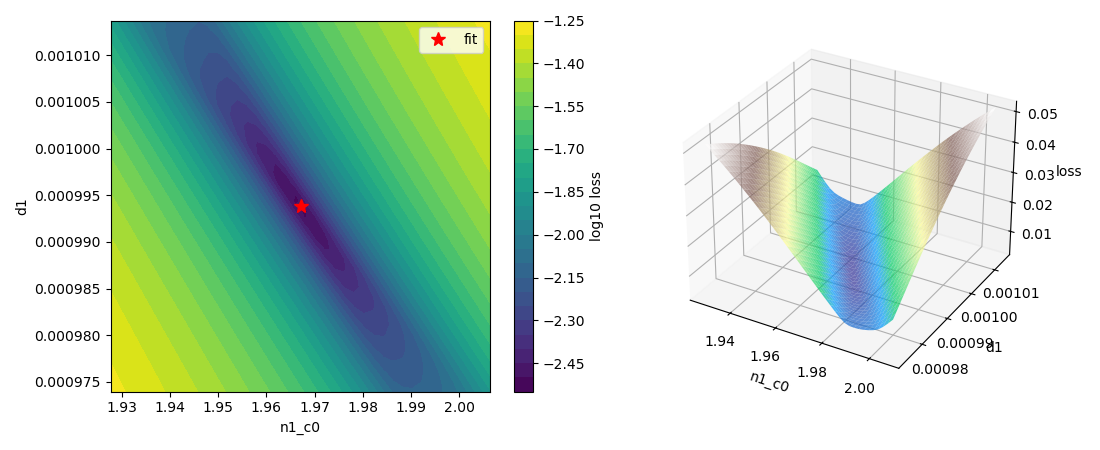

  0%|          | 0/40 [00:00<?, ?it/s]

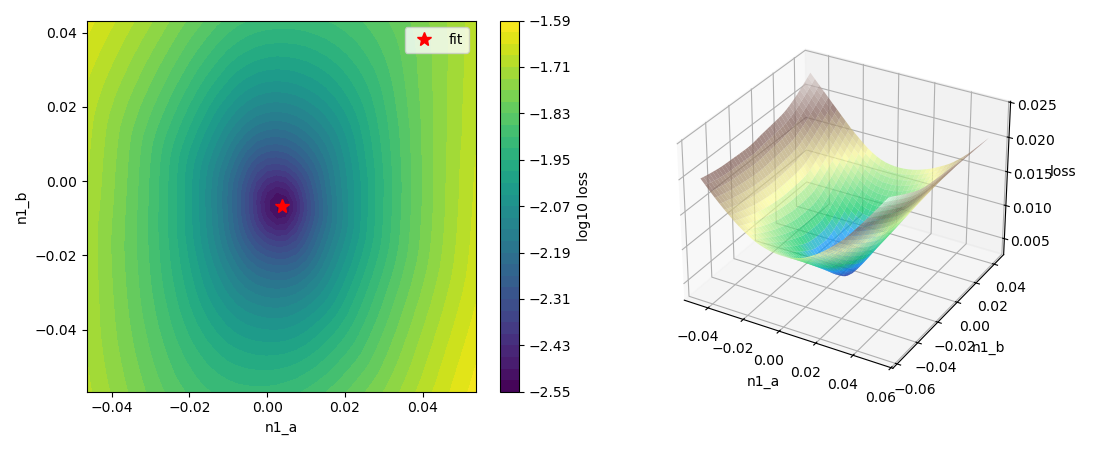

  0%|          | 0/40 [00:00<?, ?it/s]

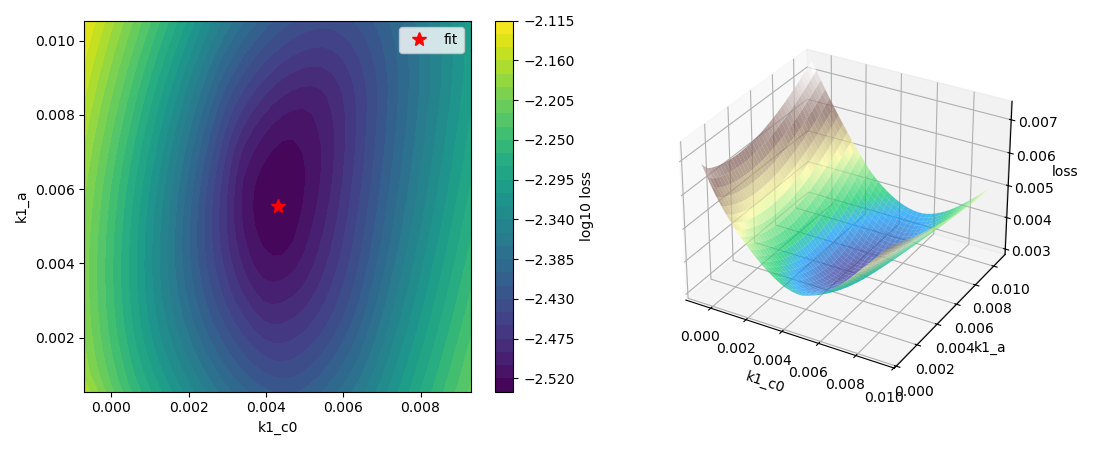

In [48]:
RUN_LANDSCAPES = True
if RUN_LANDSCAPES:
    # c0 of n vs thickness: the optical-path valley (relative +-2 %)
    X_, Y_, Z_, c_ = loss_landscape(model, 'n1_c0', 'd1', n_pts=40, span_x=0.02, span_y=0.02)
    plot_landscape(X_, Y_, Z_, c_, 'n1_c0', 'd1')

    # linear vs quadratic dispersion term of quartz: how flat is the landscape? (absolute +-0.05 in index units)
    X_, Y_, Z_, c_ = loss_landscape(model, 'n1_a', 'n1_b', n_pts=40, span_x=0.05, span_y=0.05, absolute=True)
    plot_landscape(X_, Y_, Z_, c_, 'n1_a', 'n1_b')

    # absorption slope vs offset of quartz (absolute +-0.005)
    X_, Y_, Z_, c_ = loss_landscape(model, 'k1_c0', 'k1_a', n_pts=40, span_x=0.005, span_y=0.005, absolute=True)
    plot_landscape(X_, Y_, Z_, c_, 'k1_c0', 'k1_a')

## Notes / knobs

* **Band** `F_LO, F_HI`: from the spectrum plot, the sample signal is ≳ 10× above the noise floor between
  ~0.2 and ~3 THz. Widen the band only if the spectral-residual plot shows structure you want to fit.
* **Polynomial order**: $n$ is cubic, $k$ quadratic. To make $n$ quadratic too, freeze its cubic term with
  `model.n_mask[:, 3] = 0` (or drop the name from `N_COEF_NAMES` and the 4th entries of `n_init`/`n_scale`).
  For a material with a phonon line, a polynomial is the wrong basis — swap `poly` for a Lorentz/Debye
  term in `DispersiveTwoLayer.nk`; nothing else needs to change.
* **Scales** (`n_scale`, `k_scale`): they set how far Adam moves each coefficient per iteration
  (≈ `lr × scale`). Defaults: 0.1 index units per unit $x$ for $n$, 0.005 for $k$.
* **Fixing $k$**: `model.set_absorption(False)` behaves like the commented `k1.requires_grad = False` lines of the
  original notebook.
* **Positivity of $k$**: soft, via `K_POS_WEIGHT` (section 5). `model.report()` prints the fraction of the band
  where $k<0$, and the loss plot shows the penalty part separately; if it is not negligible at the end, the data
  really want $k<0$ there (usually the low-SNR band edges) — widen/narrow the band or raise the weight.
  Set `K_POS_WEIGHT = 0` to see the unconstrained solution.